# Proj5 ra, dec derivatives

## "Derivation"

In [1]:
using SymPy, PyCall
latex(exp) = clipboard(SymPy.latex(exp))

@vars x y δ₀ α₀ real=true

ρ = sqrt(x^2 + y^2)
c = 2*asin(1/2 * ρ)

δ = asin(cos(c) * sin(δ₀) - y * sin(c)*cos(δ₀) / ρ)
α = α₀ + atan(x * sin(c) / (ρ * cos(δ₀) * cos(c) + y * sin(δ₀) * sin(c)))

@vars delta_0 alpha_0 rho c
sub =(δ₀ => delta_0, α₀ => alpha_0, 2*asin(0.5*sqrt(x^2+y^2)) => c, sqrt(x^2+y^2) => rho);

### $\nabla \delta$

In [2]:
dδdx = diff(δ, x)(sub...)

       1.0⋅x⋅sin(c)⋅sin(δ₀)             1.0⋅x⋅y⋅cos(c)⋅cos(δ₀)       x⋅y⋅sin(c
- ────────────────────────────── - ─────────────────────────────── + ─────────
       _________________________         _________________________            
      ╱         2         2         2   ╱         2         2                ρ
  ρ⋅╲╱  - 0.25⋅x  - 0.25⋅y  + 1    ρ ⋅╲╱  - 0.25⋅x  - 0.25⋅y  + 1             
──────────────────────────────────────────────────────────────────────────────
                         ___________________________________________          
                        ╱                                         2           
                       ╱      ⎛                  y⋅sin(c)⋅cos(δ₀)⎞            
                      ╱   1 - ⎜-sin(δ₀)⋅cos(c) + ────────────────⎟            
                    ╲╱        ⎝                         ρ        ⎠            

)⋅cos(δ₀)
─────────
3        
         
         
─────────
         
         
         
         
         

Written a little more nicely, using $h = \sqrt{-0.25x^2 -0.25y^2 +1} = \sqrt{1 - \left(\frac{\rho}{2}\right)^2}$:

$$
\nabla_x \delta = \frac{x  \left(  \frac{y \sin{c} \cos{\delta_{0}}}{\rho^{3}} - \frac{y \cos{c} \cos{\delta_{0}}}{\rho^{2} h} - \frac{\sin{c} \sin{\delta_{0}}}{\rho h} \right)}{
\sqrt{1 - \left(\frac{y \sin{c} \cos{\delta_{0}}}{\rho} - \sin{\delta_{0} } \cos{c}\right)^{2}}}
$$

But since
$$\begin{align*}
\sin c &= \sin \left (2 \sin^{-1} \frac{\rho}{2} \right) = \rho \sqrt{1 - \left(\frac{\rho}{2} \right)^2} = \rho h \\
\cos c &= \cos \left (2 \sin^{-1} \frac{\rho}{2} \right) = 1 - \frac{\rho^2}{2} = g^2 \\
\end{align*}$$

The derivative can be written in the much simpler form

$$
\begin{align*}
\nabla_x \delta &= \frac{x  \left(  \frac{y \rho h \cos{\delta_{0}}}{\rho^{3}} - \frac{y g^2 \cos{\delta_{0}}}{\rho^{2} h} - \frac{\rho h \sin{\delta_{0}}}{\rho h} \right)}{
\sqrt{1 - \left(\frac{y \rho h \cos{\delta_{0}}}{\rho} - \sin{\delta_{0} } g^2\right)^{2}}} \\
%
&= - \frac{x}{\rho^2 h} \frac{(h^2 - g^2) y \cos{\delta_{0}} - \rho^2 h \sin{\delta_{0}}}{\sqrt{1 - \left(y h \cos{\delta_{0}} -  g^2 \sin{\delta_{0} }\right)^{2}}}
\end{align*}
$$

In [3]:
dδdy = diff(δ, y)(sub...)

                                                              2               
       1.0⋅y⋅sin(c)⋅sin(δ₀)        sin(c)⋅cos(δ₀)        1.0⋅y ⋅cos(c)⋅cos(δ₀)
- ────────────────────────────── - ────────────── - ──────────────────────────
       _________________________         ρ                ____________________
      ╱         2         2                          2   ╱         2         2
  ρ⋅╲╱  - 0.25⋅x  - 0.25⋅y  + 1                     ρ ⋅╲╱  - 0.25⋅x  - 0.25⋅y 
──────────────────────────────────────────────────────────────────────────────
                                 ___________________________________________  
                                ╱                                         2   
                               ╱      ⎛                  y⋅sin(c)⋅cos(δ₀)⎞    
                              ╱   1 - ⎜-sin(δ₀)⋅cos(c) + ────────────────⎟    
                            ╲╱        ⎝                         ρ        ⎠    

         2               
        y ⋅sin(c)⋅cos(δ₀)

Again writing in simpler form:
$$
\begin{align*}
\nabla_y \delta &= \frac{- \frac{y \rho h \sin{\delta_{0}}}{\rho h} - \frac{\rho h \cos{\delta_{0}}}{\rho} - \frac{y^{2} g^2 \cos{\delta_{0}}}{\rho^{2} h} + \frac{y^{2} \rho h \cos{\delta_{0}}}{\rho^{3}}}{\sqrt{1 - \left(\frac{y \rho h \cos{\delta_{0}}}{\rho} - g^2 \sin{\delta_{0}} \right)^{2}}} \\
%
&= - \frac{y[(h^2 - g^2) y \cos{\delta_{0}} - \rho^2 h \sin{\delta_{0}}] - \rho^2 h^2 \cos{\delta_{0}}}{\rho^2 h \sqrt{1 - \left(y h \cos{\delta_{0}} -  g^2 \sin{\delta_{0}} \right)^{2}}} \\
\end{align*}
$$



In [4]:
py"""
import numpy as np
def grad_delta(x, y, d0):
    rho = np.sqrt(x**2 + y**2)
    h = np.sqrt(1 - rho**2 / 4)
    g = np.sqrt(1 - rho**2 / 2)

    denominator = rho**2 * h * np.sqrt(1 - (y*h*np.cos(d0) - g**2 * np.sin(d0))**2)
    c = (h**2 - g**2) * y * np.cos(d0) - rho**2 * h * np.sin(d0)
    
    grad_x =  x * c / denominator
    grad_y =   (y * c - (rho*h)**2 * np.cos(d0)) / denominator
    
    return grad_x, grad_y
"""

### $\nabla \alpha$

In [5]:
dαdx = (diff(α, x)(sub...))

  ⎛    1.0⋅x⋅sin(c)⋅cos(δ₀)           1.0⋅x⋅y⋅sin(δ₀)⋅cos(c)       x⋅cos(c)⋅co
x⋅⎜──────────────────────────── - ────────────────────────────── - ───────────
  ⎜   _________________________        _________________________          ρ   
  ⎜  ╱         2         2            ╱         2         2                   
  ⎝╲╱  - 0.25⋅x  - 0.25⋅y  + 1    ρ⋅╲╱  - 0.25⋅x  - 0.25⋅y  + 1               
──────────────────────────────────────────────────────────────────────────────
                                                                2             
                           (ρ⋅cos(c)⋅cos(δ₀) + y⋅sin(c)⋅sin(δ₀))              
                                                                              
──────────────────────────────────────────────────────────────────────────────
                                                                              
                                                                              
                                                    

\begin{align*}
\nabla_x \alpha &= \frac{\frac{x \left(\frac{x \rho h \cos{\delta_{0}}}{h} - \frac{x y \sin{\delta_{0}} g^2}{\rho h} - \frac{x g^2 \cos{\delta_{0}}}{\rho}\right) \rho h}{\left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{2}} + \frac{\rho h}{\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}} + \frac{x^{2} g^2}{\rho \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right) h}}{\frac{x^{2} (\rho h)^2}{\left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{2}} + 1} \\
%
&= \frac{\frac{x^2 \left(\rho^2 h \cos{\delta_{0}} - y g^2 \sin{\delta_{0}} - h g^2 \cos{\delta_{0}}\right)}{\left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{2}} + \frac{\rho h}{\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}} + \frac{x^{2} g^2}{\rho h \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)}}{\left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{-2} \left((x \rho h)^2 + \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{2}\right)} \\
% 
&= 
\frac{
  x^2 \left(\rho^2 h \cos{\delta_{0}} - y g^2 \sin{\delta_{0}} - h g^2 \cos{\delta_{0}}\right)
  + (xg)^{2} (\rho h)^{-1} \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)
  + \rho h \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right) 
}
{
  (x \rho h)^2 + \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{2}
} \\
%
&= 
\frac{
  x^2 \cos{\delta_{0}} \left(\rho^2 h + g^4 h^{-1} - h g^2 \right)
  + \rho^2 h \left(g^2 \cos{\delta_{0}} + y h \sin{\delta_{0}}\right) 
}
{
  (x \rho h)^2 + \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{2}
} \\
\end{align*}

In [6]:
dαdy = diff(α, y)(sub...)

  ⎛                                                         2                 
  ⎜    1.0⋅y⋅sin(c)⋅cos(δ₀)                            1.0⋅y ⋅sin(δ₀)⋅cos(c)  
x⋅⎜──────────────────────────── - sin(c)⋅sin(δ₀) - ───────────────────────────
  ⎜   _________________________                         ______________________
  ⎜  ╱         2         2                             ╱         2         2  
  ⎝╲╱  - 0.25⋅x  - 0.25⋅y  + 1                     ρ⋅╲╱  - 0.25⋅x  - 0.25⋅y  +
──────────────────────────────────────────────────────────────────────────────
                                                                        2     
                                   (ρ⋅cos(c)⋅cos(δ₀) + y⋅sin(c)⋅sin(δ₀))      
                                                                              
──────────────────────────────────────────────────────────────────────────────
                                                                              
                                                    

\begin{align*}
\nabla_y \alpha &= 
\frac{
      \frac{x \rho h \left(\frac{y \rho h \cos{\delta_{0}}}{h} 
            - \rho h \sin{\delta_{0}} 
            - \frac{y^{2}  g^2 \sin{\delta_{0}}}{\rho h} 
            - \frac{y g^2 \cos{\delta_{0}}}{\rho}\right)}
           {\left(\rho g^2 \cos{\delta_{0}}  + y \rho h \sin{\delta_{0}}\right)^{2}} 
      + \frac{x y g^2}
             {\rho \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right) h}}
{\left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{-2} 
 \left((x \rho h)^2 + \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{2}\right)} \\
&= 
x \frac{
      \rho h \left(\frac{y \rho h \cos{\delta_{0}}}{h} 
      - \rho h \sin{\delta_{0}} 
      - \frac{y^{2}  g^2 \sin{\delta_{0}}}{\rho h} 
      - \frac{y g^2 \cos{\delta_{0}}}{\rho}\right)
      + y g^2 (h \rho)^{-1} \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)}
{(x \rho h)^2 + \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{2}} \\
&= 
x \frac{
      \left(y \rho^2 h \cos{\delta_{0}} 
      - (\rho h)^2 \sin{\delta_{0}} 
      - (y g)^2 \sin{\delta_{0}} 
      - y h g^2 \cos{\delta_{0}}\right)
      + \left(y g^4 h^{-1} \cos{\delta_{0}} + (yg)^2 \sin{\delta_{0}}\right)}
{(x \rho h)^2 + \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{2}} \\
&= 
x \frac{y \cos{\delta_{0}} \left(\rho^2 h + g^4 h^{-1} - h g^2 \right)
        - (\rho h)^2 \sin{\delta_{0}} 
       }
{(x \rho h)^2 + \left(\rho g^2 \cos{\delta_{0}} + y \rho h \sin{\delta_{0}}\right)^{2}} \\
\end{align*}

In [7]:
py"""
import numpy as np
def grad_alpha(x, y, d0):
    rho = np.sqrt(x**2 + y**2)
    h = np.sqrt(1 - (rho / 2)**2)
    g = np.sqrt(1 - rho**2 / 2)

    denominator = (x * rho * h)**2 + (rho * g**2 * np.cos(d0) + y * rho * h * np.sin(d0))**2
    c = np.cos(d0) * (rho**2 * h + g**4 / h - g**2 * h)
    
    grad_x = (x**2 * c + rho**2 * h * (g**2 * np.cos(d0) + y * h * np.sin(d0))) / denominator
    grad_y = x * (y * c - (rho*h)**2 * np.sin(d0)) / denominator
    
    return grad_x, grad_y
"""

## Automatic Differentiation

[Automatic Differentiation](https://en.wikipedia.org/wiki/Automatic_differentiation) is a technique that allows us to compute derivatives to arbitrary accuracy; to use it, we need to define the Proj5 ra/dec $\iff$ x/y conversions. These come from [Wolfram Mathworld](https://mathworld.wolfram.com/LambertAzimuthalEqual-AreaProjection.html), with slight modifications to match 3G's "South is up" convention. 

For reference, the 3G implementation of xy $\to$ ra, dec is [here](https://github.com/SouthPoleTelescope/spt3g_software/blob/e24a92d5fecc9fa605ffb8b1d8cf608177c9ebc6/coordinateutils/src/flatskyprojection.cxx#L300) and the implementation of ra, dec $\to$ x, y is [here](https://github.com/SouthPoleTelescope/spt3g_software/blob/e24a92d5fecc9fa605ffb8b1d8cf608177c9ebc6/coordinateutils/src/flatskyprojection.cxx#L410).

### x, y $\to$ ra, dec

In [8]:
ρ̂(x,y) = sqrt(x^2 + y^2)
ĉ(x,y) = 2*asin(1/2 * ρ̂(x,y))

δ̂(x, y, δ₀) = asin(cos(ĉ(x,y)) * sin(δ₀) - y * sin(ĉ(x,y)) / ρ̂(x,y) * cos(δ₀))
α̂(x, y, δ₀, α₀) = α₀ + atan(x * sin(ĉ(x,y)), (ρ̂(x,y) * cos(δ₀) * cos(ĉ(x,y)) + y * sin(δ₀) * sin(ĉ(x,y))));

### ra, dec $\to$ x,y

In [9]:
k̂(δ, α, δ₀, α₀) =  sqrt(2 / (1 + sin(δ₀) * sin(δ) + cos(δ₀) * cos(δ) * cos(α - α₀)))

x̂(δ, α, δ₀, α₀) = k̂(δ, α, δ₀, α₀) * cos(δ) * sin(α-α₀)
ŷ(δ, α, δ₀, α₀) = k̂(δ, α, δ₀, α₀) * (sin(δ₀)*cos(δ)*cos(α-α₀) - cos(δ₀)*sin(δ));

### Consistency check

To check that I haven't done anything silly, I: 
1. grab the "true" 3G software coordinates: `xs_true`, `ys_true`, `δs_true` and `αs_true`.
2. using the above functions, calculate `δs_calc`, `αs_calc` from `xs_true`, `ys_true`, and `xs_calc`, `ys_calc` from `δs_true`, `αs_true`.
3. plot `true` coordinates vs. `calc` coordinates--if everything is correct, this should amount to plotting $y=x$. 

In [10]:
using PyCall
py"""
import numpy as np
from spt3g.coordinateutils import FlatSkyMap, MapProjection
from spt3g.coordinateutils.maputils import get_ra_dec_map
from spt3g.core import G3Units
"""
α₀, δ₀ = deg2rad.([50, -37.5])
m = py"FlatSkyMap(100, 1, 2*G3Units.arcmin, alpha_center=$α₀, delta_center=$δ₀, proj=MapProjection.ProjZEA)"o

αδs_true = [m.pixel_to_angle(i) for i in 0:size(m)[1]-1]
αs_true, δs_true = first.(αδs_true), last.(αδs_true)


xys_true = [m.angle_to_xy(αδs_true[i]...) for i in 1:size(m)[1]]
function pixel_scale(xys, m)
    ny, nx = py"$m.shape"
    x0, y0 = py"$m.x_center, $m.y_center"
    x_res, y_res = py"$m.x_res, $m.y_res"
    
    x_min = (x0 - nx) * x_res
    y_min = (y0 - ny) * y_res
    
    xs = @. -1. * (first(xys) * x_res + x_min);
    ys = @. -1. * (last(xys) * y_res + y_min);
    return xs, ys
end
xs_true, ys_true = pixel_scale(xys_true, m);

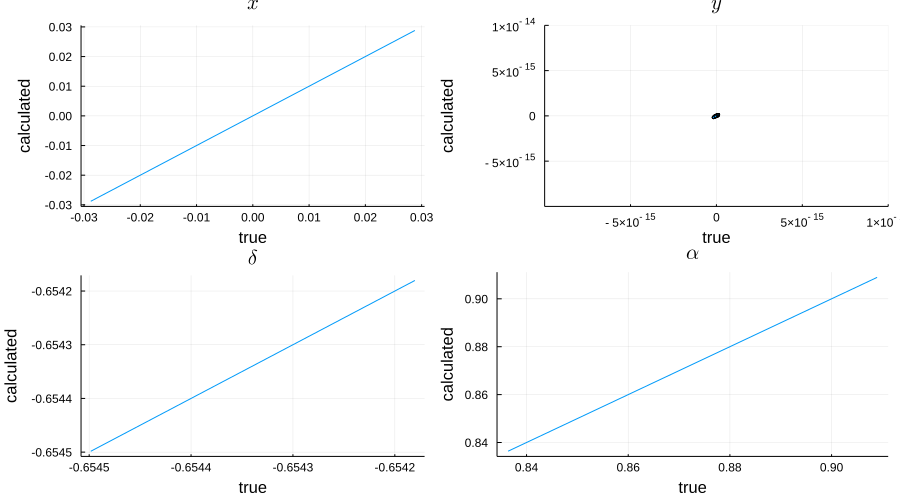

In [11]:
xs_calc = @. x̂(δs_true, αs_true, δ₀, α₀)
ys_calc = @. ŷ(δs_true, αs_true, δ₀, α₀)

δs_calc = @. δ̂(xs_true, ys_true, δ₀)
αs_calc = @. α̂(xs_true, ys_true, δ₀, α₀);

using Plots, LaTeXStrings
plot(plot(xs_true, xs_calc, title=L"x"), 
     scatter(ys_true, ys_calc, title=L"y", xlims=(-1e-14, 1e-14), ylims=(-1e-14, 1e-14), ms=1),
     plot(δs_true, δs_calc, title=L"\delta"), 
     plot(αs_true, αs_calc, title=L"\alpha"), 
     xlabel="true", ylabel="calculated", size=(900,500), legend=false)

## Gradient Comparison

Relative error is calculated as 

$$\epsilon = \frac{\left |\nabla - \nabla_\rm{analytic} \right |}{\nabla_\rm{analytic}}$$

In [19]:
using ForwardDiff: gradient
gr(lw=2; dpi=100)

function compare_gradients(; fov, res)
    m = py"FlatSkyMap(int($fov / $res), 5, $res, alpha_center=$α₀, delta_center=$δ₀, proj=MapProjection.ProjZEA)"o

    αs, δs = py"get_ra_dec_map($m)"
    xs = @. x̂(δs, αs, δ₀, α₀)
    ys = @. ŷ(δs, αs, δ₀, α₀)

    numpy_∇α = py"np.gradient($αs)[::-1]"
    numpy_∇δ = py"np.gradient($δs)[::-1]"

    xys = [[x,y] for (x,y) in zip(xs,ys)]
    forwardiff_∇α = gradient.(xy -> α̂(xy[1], xy[2], δ₀, α₀), xys) .* -py"$m.res"
    forwardiff_∇δ = gradient.(xy -> δ̂(xy[1], xy[2], δ₀), xys) .* -py"$m.res";

    analytic_∇α = py"grad_alpha($xs, $ys, $δ₀) .* $m.res"
    analytic_∇δ = py"grad_delta($xs, $ys, $δ₀) .* $m.res";
    
    pafd = plot(xlabel=L"\alpha \rm{\ (rad)}", ylabel=L"\epsilon", title=L"\nabla_{\rm{FD}} \alpha \textrm{ relative error}", yscale=:log10, legend=:bottomright)
    plot!(pafd, αs[3,:], abs.((first(numpy_∇α)[3,:] .- first(analytic_∇α)[3,:]) ./ first(analytic_∇α)[3,:]), label=L"x")
    plot!(pafd, αs[3,:], abs.((last(numpy_∇α)[3,:] .- last(analytic_∇α)[3,:]) ./ last(analytic_∇α)[3,:]), label=L"y")
    
    paad = plot(xlabel=L"\alpha \rm{\ (rad)}", ylabel=L"\epsilon", title=L"\nabla_{\rm{AD}} \alpha \textrm{ relative error}", ylims=(0,3.1e-15))
    plot!(paad, αs[3,:], abs.((first.(forwardiff_∇α[3,:]) .- first(analytic_∇α)[3,:]) ./ first(analytic_∇α)[3,:]), label=L"x")
    plot!(paad, αs[3,:], abs.((last.(forwardiff_∇α[3,:]) .- last(analytic_∇α)[3,:]) ./ last(analytic_∇α)[3,:]), label=L"y")
    
    pdfd = plot(xlabel=L"\delta \rm{\ (rad)}", ylabel=L"\epsilon", title=L"\nabla_{\rm{FD}} \delta \textrm{ relative error}", yscale=:log10, legend=:bottomright)
    plot!(pdfd, δs[3,:], abs.((first(numpy_∇δ)[3,:] .- first(analytic_∇δ)[3,:]) ./ first(analytic_∇δ)[3,:]), label=L"x")
    plot!(pdfd, δs[3,:], abs.((last(numpy_∇δ)[3,:] .- last(analytic_∇δ)[3,:]) ./ last(analytic_∇δ)[3,:]), label=L"y")
    
    pdad = plot(xlabel=L"\delta \rm{\ (rad)}", ylabel=L"\epsilon", title=L"\nabla_{\rm{AD}} \delta \textrm{ relative error}", ylims=(0,3.1e-15))
    plot!(pdad, δs[3,:], abs.((first.(forwardiff_∇δ[3,:]) .- first(analytic_∇δ)[3,:]) ./ first(analytic_∇δ)[3,:]), label=L"x")
    plot!(pdad, δs[3,:], abs.((last.(forwardiff_∇δ[3,:]) .- last(analytic_∇δ)[3,:]) ./ last(analytic_∇δ)[3,:]), label=L"y")
    
    pscale = 1
    plot(pafd, pdfd, paad, pdad, layout=(2,2), size=(900/pscale,550/pscale), dpi=100*pscale)
    
end

compare_gradients (generic function with 1 method)

### 8 arcmin

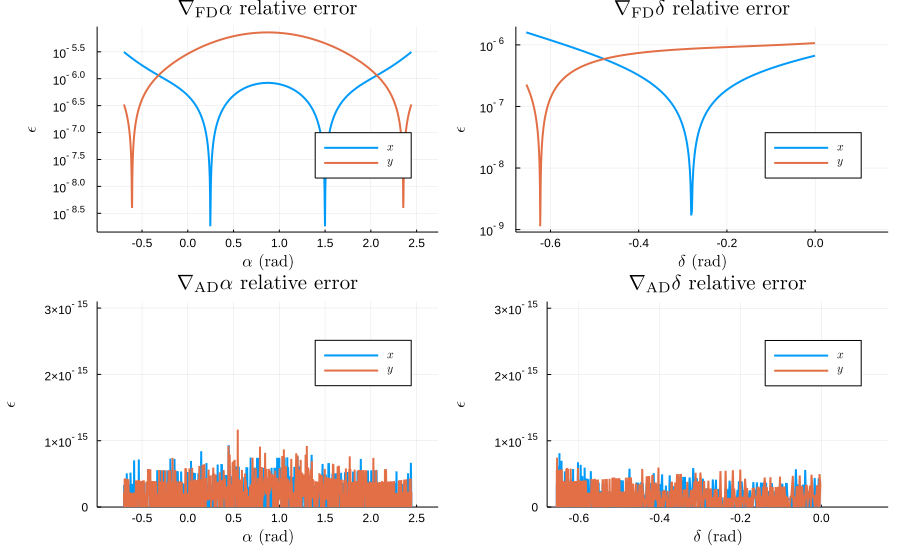

In [21]:
compare_gradients(fov=π, res=8*py"G3Units.arcmin")

### 2 arcmin

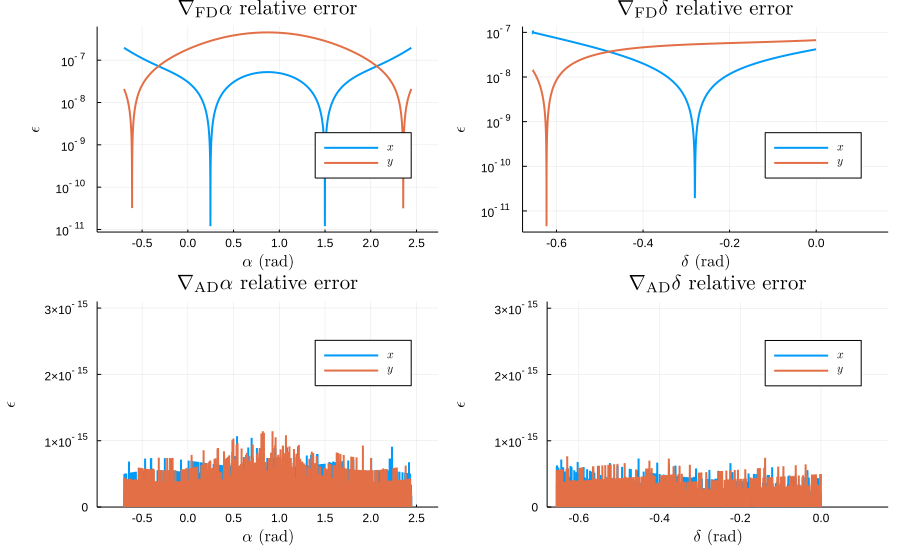

In [22]:
compare_gradients(fov=π, res=2*py"G3Units.arcmin")

### 0.25 arcmin

In [23]:
compare_gradients(fov=π, res=0.25*py"G3Units.arcmin")